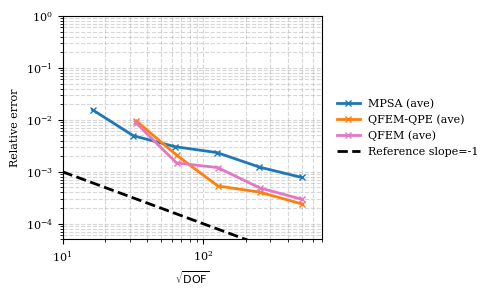

In [7]:
# Only for plot SIF results for all grid sizes
from __future__ import annotations
from dataclasses import dataclass

import numpy as np
import math
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.ticker import ScalarFormatter
from matplotlib.ticker import LogLocator, LogFormatterMathtext

# MPSA
mpsa_dofs = np.array([
    16.32151574, 31.82437906, 62.97294016, 125.48940643, 250.10555251, 499.25663341
])

err_ave_mpsa = np.array([
    0.01560495, 0.00494485, 0.00304355, 0.0023395, 0.00123267, 0.00078003
]) 

# QFEM-QPE
femqpe_dofs = np.array([
     33.48983621, 64.52259576, 126.83203562, 251.86973768, 501.1059267 
])

err_ave_femqpe = np.array([
    0.0094868, 0.00209868, 0.00053325, 0.00040623, 0.00024107
]) 


# QFEM no qpe
fem_dofs = np.array([
    33.48983621, 64.52259576, 126.83203562, 251.86973768, 501.1059267
])

err_ave_fem = np.array([
    0.00857427, 0.00148248, 0.00120427, 0.00049011, 0.00029562
]) 

# Reference line
num_dofs_line = np.array([10, 30, 50, 70, 90, 100, 300, 500, 1000])
initial_value_line = 1e-3
first_order_line = initial_value_line * (num_dofs_line[0] / num_dofs_line)
half_order_line = initial_value_line  * (num_dofs_line[0] / num_dofs_line) ** 0.5

# Plot SIF KI
mpl.rcParams.update({
    "font.family": "serif",     
    "font.size": 8,             
    "axes.labelsize": 8,       
    "axes.titlesize": 8,        
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "lines.linewidth": 1.0,      
    "lines.markersize": 3.0,       
    "mathtext.fontset": "dejavusans",  
})
formatter = ScalarFormatter(useMathText=True)
formatter.set_powerlimits((0, 0))   # Scientific form

fig, ax = plt.subplots(figsize=(5.0, 3.0))   # inches
# MPSA
ax.loglog(
    mpsa_dofs,
    err_ave_mpsa,
    'x-',
    color='tab:blue',
    linewidth=2.0, 
    markersize=4.0,
    label="MPSA (ave)"
)

# QFEM-QPE
ax.loglog(
    femqpe_dofs,
    err_ave_femqpe,
    'x-',
    color='tab:orange',
    linewidth=2.0, 
    markersize=4.0,
    label="QFEM-QPE (ave)"
)

# QFEM
ax.loglog(
    fem_dofs,
    err_ave_fem,
    'x-',
    color='tab:pink',
    linewidth=2.0, 
    markersize=4.0,
    label="QFEM (ave)"
)

ax.loglog(
    num_dofs_line, first_order_line,
    '--', color='k',
    linewidth=2.0,
    label="Reference slope=-1"
)

ax.xaxis.set_major_formatter(formatter)
ax.yaxis.set_major_formatter(formatter)
ax.set_xlim(10, 700)
ax.set_ylim(0.00005, 1.0)
ax.xaxis.set_major_locator(LogLocator(base=10))
ax.xaxis.set_major_formatter(LogFormatterMathtext())
ax.xaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1))

ax.yaxis.set_major_locator(LogLocator(base=10))
ax.yaxis.set_major_formatter(LogFormatterMathtext())
ax.yaxis.set_minor_locator(LogLocator(base=10, subs=np.arange(2, 10) * 0.1))

ax.set_xlabel(r"$\sqrt{\mathrm{DOF}}$")
ax.set_ylabel("Relative error")

# ax.legend(loc="lower left")
ax.legend(
    loc="center left",
    bbox_to_anchor=(1.02, 0.5),  
    frameon=False
)
ax.grid(True, which="both", linestyle="--", alpha=0.5)
plt.tight_layout()
# plt.savefig("KI_convergence_so.tiff", format="tiff", dpi=300, bbox_inches="tight", pil_kwargs={"compression": "tiff_lzw"})
# plt.savefig("sneddon_singularity.eps", format="eps", dpi=300, bbox_inches="tight")
plt.show()